# ML-09 — Validation and Research Claim Audit

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Epinnn14/Flyrank-ML-Intern/blob/main/work/notebooks/w06_validation_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Two paper findings + my methodology questions

*Pick two findings from the FlyRank research paper. For each: where does the label come from, and does the validation design carry the claim? Constructive tone.*

I picked two findings from *The State of AI-Driven SEO in Numbers* (FlyRank, March 2026,
`docs/flyrank-seo-research-march-2026.pdf`). The paper is written for a broad audience and is
open about its standards ("direct aggregate comparisons lead… ML pages are exploratory"). The
questions below are the ones I would want someone to ask about *my* work.

**Finding A — "The Anatomy of Growing Content" (Finding #1, tagged CONFIRMED).**
Growing pages are reported as ~38% longer (3.2K vs 2.3K words) and ~20% younger (184 vs 230 days)
than declining pages.

- *Where does the label come from?* "Up/down" is `trend_direction`: last-30-days vs previous-30-days
  impressions, with a ±10% band. That is a short-window momentum label, so one seasonal week or
  one tracking change can move a page between cohorts.
- *Does the design carry the claim?* It is a pooled comparison across 57 brands. Brands differ a lot
  in typical page length *and* in how many of their pages are trending down that month, so part of
  the gap could be "which brand" rather than "which kind of page". **My question:** does the length/age
  gap survive *within* brand (brand-demeaned, or a mixed model with brand as a group)?
- *What I measured on our 30k slice (code below, ±20% band, 32 clients):* the pattern does **not**
  reproduce here. Pooled, "up" pages are *older* (≈289 vs ≈236 days) and median length is about the
  same (≈2,850 vs ≈2,910 words). Within client the gaps shrink to tens of words and a few days. The share
  of "down" pages ranges from 0.28 to 0.99 between clients. This is a different, smaller slice with a
  different threshold, so it does not contradict the paper; it shows the comparison is sensitive to
  client mix and should be reported with a within-brand check.

**Finding B — "What Predicts Growth?" (ML appendix: logistic regression, "71% holdout accuracy").**

- *Where does the label come from?* Same growing/declining label as above. The paper does not say
  which classes were kept (up vs down only? stable included?), so the **base rate** behind 71% is
  unknown. 71% on a 62/38 class split is about 9 points of skill, while on 50/50 it is 21.
- *Does the validation design carry the claim?* "80/20 split" is described but not whether it is
  random or grouped by brand. If random, pages from the same brand sit in train and test, and the
  score partly measures memorising brand behaviour. Features such as "days visible" and "recent
  impressions" also share a time window with the 30-day label. **My questions:** what is the base
  rate, is the split grouped by brand (or time-based), and are the features measured strictly
  before the label window?

The paper already flags these pages as exploratory and descriptive, which is the right framing.
Below I apply the same questions to my own Week-5 model.

In [1]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import os, sys, subprocess, json, warnings
warnings.filterwarnings("ignore", category=UserWarning)

REPO_DIR = "Flyrank-ML-Intern"
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Epinnn14/Flyrank-ML-Intern"
if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("../..")
sys.path.insert(0, "scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ml_utils as mu
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("work/figures", exist_ok=True)
os.makedirs("work/outputs", exist_ok=True)

# Same cleaning as w05_model.ipynb (and scripts/01_prepare_features.py)
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
for col in mu.NUMERIC_COLUMNS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
for col in mu.CATEGORICAL_COLUMNS:
    df[col] = df[col].fillna("unknown").astype(str).replace({"": "unknown", "nan": "unknown"})
df = df[(df["impressions_90d"] > 0) & (df["content_age_days"] >= 90)].copy()
df = df.drop_duplicates(subset=["content_id"]).reset_index(drop=True)
df["is_declining_label"] = (df["trend_direction"] == "down").astype(int)
for c in ["impressions_90d", "clicks_90d", "sessions_90d", "ai_sessions_90d"]:
    df["log_" + c] = np.log1p(df[c].fillna(0))

print(f"Rows: {len(df):,} | clients: {df['client_id'].nunique()} | base rate (declining): {df['is_declining_label'].mean():.3f}")

# --- Paper Finding #1 analogue on our slice: growing ("up") vs declining ("down") pages ---
updown = df[df["trend_direction"].isin(["up", "down"])].copy()
raw = updown.groupby("trend_direction").agg(
    n=("content_id", "size"),
    median_words=("word_count", "median"),
    mean_age_days=("content_age_days", "mean"),
)
print("\nRaw cohort comparison (pooled across all clients):")
print(raw.round(1))

# Same comparison, but WITHIN client: subtract each client's mean first,
# so a gap can't come from "client A writes long pages AND happens to be growing".
for col in ["word_count", "content_age_days"]:
    updown[col + "_within"] = updown[col] - updown.groupby("client_id")[col].transform("mean")
within = updown.groupby("trend_direction")[["word_count_within", "content_age_days_within"]].mean()
print("\nWithin-client gap (value minus own client's mean):")
print(within.round(1))

mix = pd.crosstab(updown["client_id"], updown["trend_direction"], normalize="index")["down"]
print(f"\nShare of 'down' among up/down pages, per client: min {mix.min():.2f}, "
      f"median {mix.median():.2f}, max {mix.max():.2f}  -> client mix varies a lot")

Rows: 30,000 | clients: 32 | base rate (declining): 0.542

Raw cohort comparison (pooled across all clients):
                     n  median_words  mean_age_days
trend_direction                                    
down             16262        2909.0          236.2
up                4388        2847.5          288.5

Within-client gap (value minus own client's mean):
                 word_count_within  content_age_days_within
trend_direction                                            
down                           9.8                     -2.2
up                           -45.1                      8.3

Share of 'down' among up/down pages, per client: min 0.28, median 0.80, max 0.99  -> client mix varies a lot


## 2. My model under an honest split (before/after)

*Re-run your Week-5 model under a grouped or time-aware split. Show both numbers.*

**Before:** my Week-5 Random Forest used one 80/20 client holdout (6 test clients). That single
draw had a test base rate of 0.39 vs 0.55 in train, so one lucky or unlucky split can move the
headline a lot. For a clean comparison I re-run the *same* features under two designs, 5 folds each:

1. **Random row split (StratifiedKFold)**: what most tutorials do.
2. **Client-grouped split (GroupKFold by `client_id`)**: whole clients are held out, which matches
   the real question: "does this work on a client the model has never seen?"

**What changed (measured, 5-fold means):**

| Design | ROC AUC | Avg precision | Precision@50 | Base rate |
|---|---|---|---|---|
| Random row split | 0.772 | 0.788 | 0.968 | 0.542 |
| Client-grouped | 0.668 (sd 0.05) | 0.674 | 0.748 | 0.544 (0.38–0.65 per fold) |

The ~0.10 AUC gap is the size of the memorisation effect: under a random split the forest learns
each client's "fingerprint". The grouped number is the one I keep. The per-fold spread (AUC
0.61–0.74) is part of the result: performance depends on which clients are held out.

Week-5 Random Forest, same features, two validation designs (5 folds each):
                             base_rate       roc_auc        avg_precision        precision_at_50        precision_at_100       
                                  mean   std    mean    std          mean    std            mean    std             mean    std
setup                                                                                                                          
AFTER: client-grouped 5-fold     0.544  0.11   0.668  0.048         0.674  0.053           0.748  0.150            0.722  0.116
BEFORE: random row split         0.542  0.00   0.772  0.006         0.788  0.006           0.968  0.023            0.950  0.025

Memorisation gap (ROC AUC random - grouped): 0.104
Per-fold base rate under grouped split: [0.49, 0.65, 0.38, 0.62, 0.58]
Per-fold ROC AUC under grouped split:   [0.661, 0.608, 0.742, 0.659, 0.669]


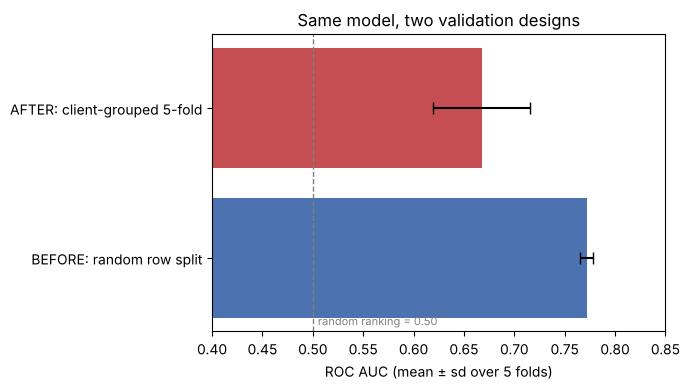

In [2]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

y = df["is_declining_label"].to_numpy()
groups = df["client_id"].to_numpy()

def build_X(num_cols, cat_cols):
    num = df[num_cols].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0)
    cat = pd.get_dummies(df[cat_cols].astype(str), prefix=cat_cols, dtype=float) if cat_cols else pd.DataFrame(index=df.index)
    return pd.concat([num, cat], axis=1)

def make_rf():
    # Same family as the Week-5 winner; a little regularised so 5 folds run fast.
    return RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                                  n_jobs=-1, random_state=RANDOM_STATE)

def evaluate(X, splitter, label):
    rows = []
    for fold, (tr, te) in enumerate(splitter.split(X, y, groups)):
        model = make_rf().fit(X.iloc[tr], y[tr])
        p = model.predict_proba(X.iloc[te])[:, 1]
        rows.append({
            "setup": label, "fold": fold,
            "base_rate": y[te].mean(),
            "roc_auc": roc_auc_score(y[te], p),
            "avg_precision": average_precision_score(y[te], p),
            "precision_at_50": mu.precision_at_k(y[te], p, 50),
            "precision_at_100": mu.precision_at_k(y[te], p, 100),
        })
    return pd.DataFrame(rows)

X_week5 = build_X(mu.MODEL_NUMERIC_FEATURES, mu.MODEL_CATEGORICAL_FEATURES)

before = evaluate(X_week5, StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), "BEFORE: random row split")
after = evaluate(X_week5, GroupKFold(5), "AFTER: client-grouped 5-fold")
folds = pd.concat([before, after])

summary = folds.groupby("setup")[["base_rate", "roc_auc", "avg_precision", "precision_at_50", "precision_at_100"]].agg(["mean", "std"]).round(3)
print("Week-5 Random Forest, same features, two validation designs (5 folds each):")
print(summary)

gap = before["roc_auc"].mean() - after["roc_auc"].mean()
print(f"\nMemorisation gap (ROC AUC random - grouped): {gap:.3f}")
print("Per-fold base rate under grouped split:", after["base_rate"].round(2).tolist())
print("Per-fold ROC AUC under grouped split:  ", after["roc_auc"].round(3).tolist())

fig, ax = plt.subplots(figsize=(7, 4))
plot = folds.groupby("setup")["roc_auc"].agg(["mean", "std"]).iloc[::-1]
ax.barh(plot.index, plot["mean"], xerr=plot["std"], color=["#4C72B0", "#C44E52"], capsize=4)
ax.axvline(0.5, ls="--", color="grey", lw=1)
ax.text(0.505, -0.45, "random ranking = 0.50", fontsize=8, color="grey")
ax.set_xlim(0.4, 0.85)
ax.set_xlabel("ROC AUC (mean ± sd over 5 folds)")
ax.set_title("Same model, two validation designs")
plt.tight_layout()
plt.savefig("work/figures/w06_split_before_after.png", dpi=150)
plt.show()

## 3. Leakage audit

*The same hunt from Week 3, on your final feature set.*

The Week-3 hunt, repeated on the final feature set, plus one check I had missed before.

1. **Label-derived columns.** `trend_pct` / `trend_direction` are not in the features. As a harness
   check I add `trend_pct` on purpose: grouped AUC goes to **1.00**, so the test setup would catch
   this kind of leak.
2. **Window overlap (new finding).** The label compares *days 1–30 back* with *days 31–60 back*.
   Every `*_90d` total, `ctr`, `engagement_rate`, `scroll_rate` and `days_with_*` covers days 1–90,
   so it **contains the label window**. In a real deployment I would predict at day 30-back, when
   days 1–30 have not happened yet. I rebuilt a **window-aligned** feature set from days 31–90 only:
   previous-30-day and first-30-day impressions/clicks/sessions (the first window is
   `90d − last30 − prev30`), an *early momentum* feature (prev30 vs first30), content metadata and
   missingness flags.
3. **Export-time freshness.** 68% of pages had their last update *inside* the label window, so
   `days_since_last_update` / `freshness_tier` describe the future relative to the prediction moment.
   I dropped them from the aligned set.
4. **IDs** (`content_id`, `client_id`) are used only for grouping, never as features.

**Result (client-grouped 5-fold):** the window-aligned model scores **ROC AUC 0.685 (sd 0.08)**,
average precision 0.677 and precision@50 0.668, against a base rate of 0.544. That is about the same
as the overlapping set (0.668), so the overlap was **not** secretly inflating the Week-5 score.
Still, the aligned set is the one I can defend, and it is the version I carry into the playbook and
the paper. The model leans most on content age and earlier impression levels. Its most confident
mistakes are keyword articles about 120–150 days old that it flags but which stayed stable, and
older (~440-day) pages with no word-count data that it misses. Error rate at the 0.5 threshold is
high (~44% on this fold), so this is a **ranking aid for review order, not a yes/no verdict**.

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# 1) Label-derived columns must not be features
feats = list(X_week5.columns)
for suspect in ["trend_pct", "trend_direction", "is_declining_label"]:
    print(f"{suspect:>20} in Week-5 features? {any(f.startswith(suspect) for f in feats)}")

# 2) Harness check: deliberately ADD the label source. The score should jump to ~1.0.
X_leak = X_week5.copy()
X_leak["trend_pct"] = df["trend_pct"].fillna(0)
leak = evaluate(X_leak, GroupKFold(5), "LEAK TEST: + trend_pct")
print(f"\nWith trend_pct added (grouped CV): ROC AUC = {leak['roc_auc'].mean():.3f}  -> harness detects leakage")

# 3) Window overlap. The label compares days 1-30 back vs days 31-60 back.
#    Every *_90d column (and ctr, engagement_rate, scroll_rate, days_with_*) covers days 1-90,
#    so it CONTAINS the label window. Rebuild features that only use days 31-90 back,
#    i.e. what was knowable at the moment we would have made the prediction.
df["impr_first30"] = (df["impressions_90d"] - df["impressions_last_30d"].fillna(0) - df["impressions_prev_30d"].fillna(0)).clip(lower=0)
df["clicks_first30"] = (df["clicks_90d"] - df["clicks_last_30d"].fillna(0) - df["clicks_prev_30d"].fillna(0)).clip(lower=0)
df["sessions_first30"] = (df["sessions_90d"] - df["sessions_last_30d"].fillna(0) - df["sessions_prev_30d"].fillna(0)).clip(lower=0)
for c, src in [("log_impr_prev30", "impressions_prev_30d"), ("log_clicks_prev30", "clicks_prev_30d"),
               ("log_sessions_prev30", "sessions_prev_30d")]:
    df[c] = np.log1p(df[src].fillna(0))
for c in ["impr_first30", "clicks_first30", "sessions_first30"]:
    df["log_" + c] = np.log1p(df[c])
df["early_momentum"] = df["log_impr_prev30"] - df["log_impr_first30"]   # trend BEFORE the label window
for c in ["search_volume", "word_count"]:
    df["has_" + c] = df[c].notna().astype(int)                          # missingness flags instead of silent 0

ALIGNED_NUMERIC = ["search_volume", "competition", "cpc", "word_count", "has_search_volume", "has_word_count",
                   "content_age_days", "log_impr_prev30", "log_impr_first30", "log_clicks_prev30",
                   "log_clicks_first30", "log_sessions_prev30", "log_sessions_first30", "early_momentum"]
ALIGNED_CATEGORICAL = ["competition_level", "content_type", "main_intent"]

updated_in_label_window = (df["days_since_last_update"] < 30).mean()
print(f"\nPages whose last update falls INSIDE the label window: {updated_in_label_window:.1%}")
print("-> days_since_last_update / freshness_tier are measured at export time, so they are dropped from the aligned set.")

X_aligned = build_X(ALIGNED_NUMERIC, ALIGNED_CATEGORICAL)
aligned = evaluate(X_aligned, GroupKFold(5), "AFTER+: grouped + window-aligned features")

audit = pd.concat([after, aligned, leak]).groupby("setup")[["roc_auc", "avg_precision", "precision_at_50", "precision_at_100"]].mean().round(3)
audit.loc["(base rate, grouped folds)"] = [0.5, after["base_rate"].mean().round(3), after["base_rate"].mean().round(3), after["base_rate"].mean().round(3)]
print("\nLeakage audit summary (client-grouped 5-fold):")
print(audit)

# 4) Which aligned features does the model lean on? (permutation importance on one held-out fold)
from sklearn.inspection import permutation_importance
tr, te = next(GroupKFold(5).split(X_aligned, y, groups))
m = make_rf().fit(X_aligned.iloc[tr], y[tr])
pi = permutation_importance(m, X_aligned.iloc[te], y[te], n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1, scoring="roc_auc")
imp = pd.Series(pi.importances_mean, index=X_aligned.columns).sort_values(ascending=False).head(8)
print("\nTop aligned features (permutation importance, held-out clients):")
print(imp.round(4))

# 5) Error examples (public-safe: no ids, just profiles)
p = m.predict_proba(X_aligned.iloc[te])[:, 1]
err = df.iloc[te][["content_type", "content_age_days", "word_count", "impressions_prev_30d", "early_momentum", "trend_direction"]].copy()
err["p_declining"] = p.round(2); err["actual"] = y[te]
fp = err[(err.actual == 0)].sort_values("p_declining", ascending=False).head(5)
fn = err[(err.actual == 1)].sort_values("p_declining").head(5)
print("\nMost confident FALSE POSITIVES (flagged as declining, were not):")
print(fp.to_string(index=False))
print("\nMost confident FALSE NEGATIVES (missed decliners):")
print(fn.to_string(index=False))
print("\nError rate by content_type at threshold 0.5:")
err["wrong"] = ((err.p_declining >= 0.5).astype(int) != err.actual)
print(err.groupby("content_type")["wrong"].agg(["mean", "size"]).round(3))

metrics = {
    "label": "is_declining_label (trend_direction == 'down')",
    "validation": "GroupKFold(5) by client_id",
    "base_rate_grouped_mean": round(float(after["base_rate"].mean()), 4),
    "random_split_week5_features": folds[folds.setup.str.startswith("BEFORE")][["roc_auc", "avg_precision", "precision_at_50"]].mean().round(4).to_dict(),
    "grouped_week5_features": after[["roc_auc", "avg_precision", "precision_at_50"]].mean().round(4).to_dict(),
    "grouped_aligned_features": aligned[["roc_auc", "avg_precision", "precision_at_50"]].mean().round(4).to_dict(),
    "grouped_aligned_auc_sd": round(float(aligned["roc_auc"].std()), 4),
    "leak_test_auc": round(float(leak["roc_auc"].mean()), 4),
}
with open("work/outputs/w06_validation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print("\nSaved work/outputs/w06_validation_metrics.json")

           trend_pct in Week-5 features? False
     trend_direction in Week-5 features? False
  is_declining_label in Week-5 features? False



With trend_pct added (grouped CV): ROC AUC = 1.000  -> harness detects leakage

Pages whose last update falls INSIDE the label window: 68.3%
-> days_since_last_update / freshness_tier are measured at export time, so they are dropped from the aligned set.



Leakage audit summary (client-grouped 5-fold):
                                           roc_auc  avg_precision  precision_at_50  precision_at_100
setup                                                                                               
AFTER+: grouped + window-aligned features    0.685          0.677            0.668             0.696
AFTER: client-grouped 5-fold                 0.668          0.674            0.748             0.722
LEAK TEST: + trend_pct                       1.000          1.000            1.000             1.000
(base rate, grouped folds)                   0.500          0.544            0.544             0.544



Top aligned features (permutation importance, held-out clients):
content_age_days             0.0567
log_impr_first30             0.0222
log_impr_prev30              0.0152
early_momentum               0.0139
log_clicks_prev30            0.0086
log_sessions_prev30          0.0061
search_volume                0.0030
main_intent_informational    0.0017
dtype: float64

Most confident FALSE POSITIVES (flagged as declining, were not):
   content_type  content_age_days  word_count  impressions_prev_30d  early_momentum trend_direction  p_declining  actual
keyword article               139      4618.0                  1792       -0.458857          stable         0.81       0
keyword article               119      3102.0                  1397       -0.586435          stable         0.81       0
keyword article               148      2617.0                  1006       -0.420251          stable         0.80       0
keyword article               148      2274.0                  1467       -0.2366

## 4. Claim rewrite

*Take your own boldest sentence and rewrite it in safe language: observed, measured, directional, decision-support.*

**My boldest Week-5 sentence (before):**

> ~~"Random Forest reaches Precision@50 ≈ 0.74 against the Week-4 rule's ≈ 0.22 — roughly a 3x lift
> over the rule… keyword-targeted articles have messier, more heterogeneous performance histories
> (competition, search volume, intent all vary), giving the model less clean signal."~~

**Rewritten (after):**

> "On held-out clients (5-fold, grouped by client), a Random Forest using only information available
> before the label window **ranked** pages at **precision@50 ≈ 0.67** and **ROC AUC ≈ 0.69 (sd 0.08)**,
> against a **base rate of 0.54**. That is a **measured, directional** improvement over random
> ordering, and it varies by client. We **observed** more errors on keyword articles; we did not test
> why. Use it as **decision-support** to order a human review queue, not as a forecast for any single
> page."

What changed: the single-split number became a cross-validated number with its spread; the base
rate sits next to every metric; the "3x lift" framing is gone because the Week-4 rule answered a
different question; and the explanation for keyword-article errors is marked as untested instead
of stated as fact.

In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# Banned-word scan over this notebook's own markdown (claims must stay on the honest ladder).
import re, json as _json
nb_path = "work/notebooks/w06_validation_audit.ipynb"
banned = ["proves", "causes", "will increase", "guarantee", "the algorithm rewards", "predicted google"]
md = " ".join("".join(c["source"]) for c in _json.load(open(nb_path))["cells"] if c["cell_type"] == "markdown").lower()
md_no_quotes = re.sub(r"~~.*?~~|\".*?\"|“.*?”", " ", md)  # ignore struck-through/quoted 'before' sentences
hits = {w: md_no_quotes.count(w) for w in banned if w in md_no_quotes}
print("Banned phrasing outside quoted 'before' examples:", hits or "none")
print("Final numbers carried into the paper:", _json.load(open("work/outputs/w06_validation_metrics.json"))["grouped_aligned_features"])

Banned phrasing outside quoted 'before' examples: none
Final numbers carried into the paper: {'roc_auc': 0.6845, 'avg_precision': 0.6771, 'precision_at_50': 0.668}


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.